In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# 02 - Feature engineering
Leakage-safe features: customer-history aggregates use **only earlier** rows.

In [2]:
from src.feature_engineering.features import build_features, feature_names, NUMERIC_FEATURES
clean = load_clean(); X = build_features(clean); X.shape

(59682, 41)

In [3]:
pd.DataFrame({'feature': NUMERIC_FEATURES}).assign(group=lambda d: np.where(d.feature.str.contains('_x_'), 'interaction', np.where(d.feature.str.contains('cust|ratio|secs'), 'customer history', 'transaction')))

,feature,group
0,log_amount,transaction
1,hour,transaction
2,day_of_week,transaction
3,is_night,transaction
4,is_weekend,transaction
5,is_new_device,transaction
6,is_foreign,transaction
7,ip_risk_score,transaction
8,velocity_1h,transaction
9,log_account_age,transaction


In [4]:
# leakage test: altering the LAST transaction must not alter any earlier feature row
mod = clean.copy(); mod.loc[mod.index[-1], 'amount'] = 1e6
pd.testing.assert_frame_equal(build_features(mod).iloc[:-1], X.iloc[:-1]); print('no future leakage: OK')

no future leakage: OK


<Axes: title={'center': 'Mutual information with fraud label'}>

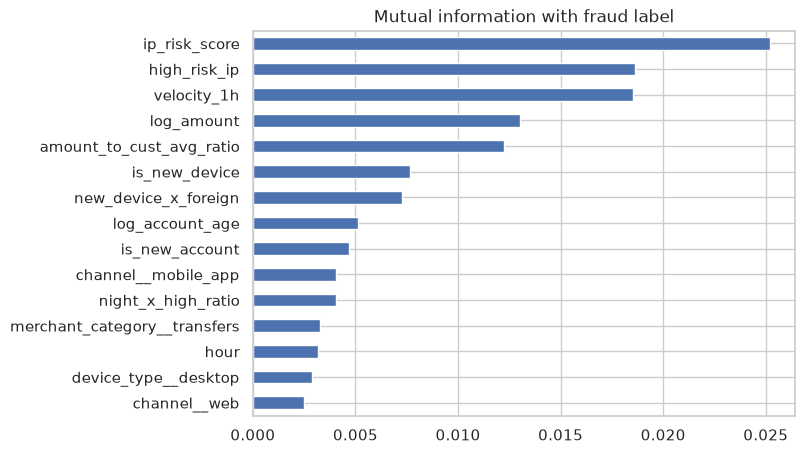

In [5]:
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(X.iloc[:20000], clean.is_fraud.iloc[:20000], random_state=0), index=X.columns).sort_values()
mi.tail(15).plot.barh(figsize=(7, 5), title='Mutual information with fraud label')

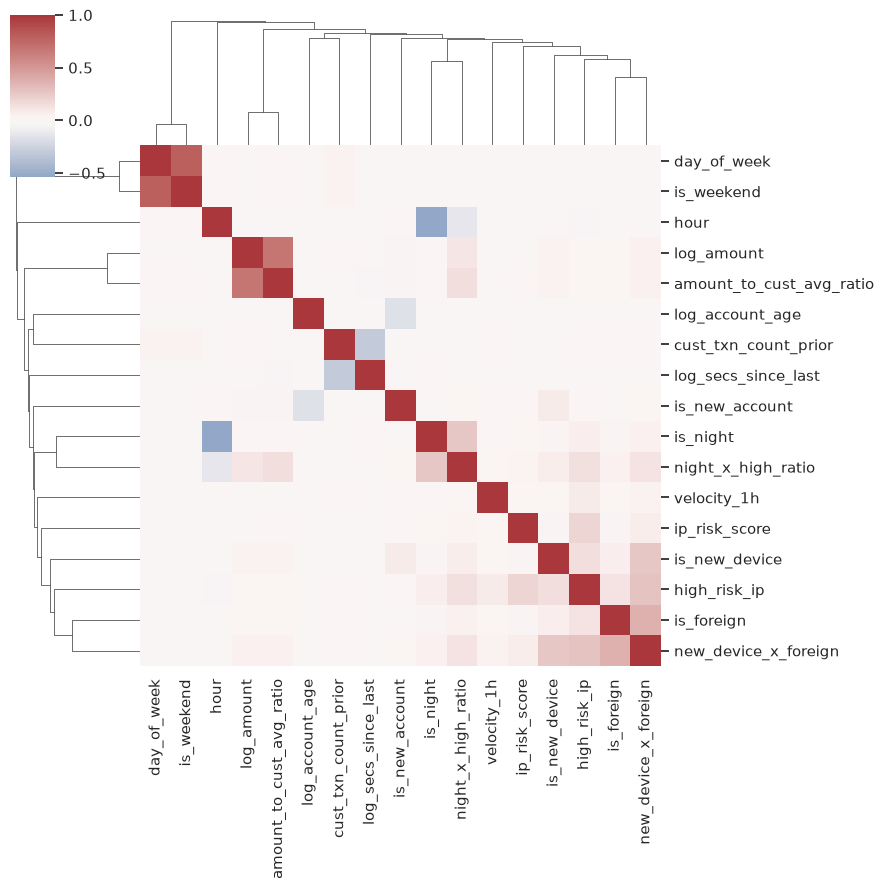

In [6]:
corr = X[NUMERIC_FEATURES].corr(method='spearman'); sns.clustermap(corr, cmap='vlag', center=0, figsize=(9, 9))

Highly correlated pairs (e.g. `is_new_device` and `new_device_x_foreign`) are tolerated: tree models are robust and Logistic Regression is L2-regularised.